*Author: Cristina. Part of the RSNA Knee Abnormality Detection team project.*

# RSNA Knee Abnormality Detection — Data Pipeline

This notebook builds the PyTorch data pipeline used to feed preprocessed knee MRI studies into the model.

The preprocessing notebook has already converted sagittal MRI studies into NumPy `.npy` files. This notebook is responsible for:

- loading the processed MRI volumes
- matching each MRI to its labels using `StudyInstanceUID`
- separating training and validation studies
- creating PyTorch `Dataset` objects
- batching studies with PyTorch `DataLoader`
- verifying that images and labels are correctly aligned
- checking image quality, label distribution, and loading speed

### Current data interface

Each study contains:

- **24 sagittal MRI slices**
- each slice is **224 × 224 pixels**
- **12 abnormality targets**

The training DataLoader therefore returns:

- Images: `(batch_size, 24, 224, 224)`
- Labels: `(batch_size, 12)`
- IDs: one `StudyInstanceUID` per study

## 1. Imports

Import the libraries needed for file handling, data manipulation, MRI loading, visualization, and PyTorch datasets.

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader

## 2. Paths and Constants

The MRI preprocessing is performed in the `02_preprocess_test_alex` notebook.

Its saved output is attached to this notebook as an input. The manifest contains the study IDs, labels, split information, and paths to the processed MRI files.

In [2]:
BASE_DIR = (
    "/kaggle/input/notebooks/"
    "alextanasescu/02-preprocess-test-alex"
)

MANIFEST_PATH = os.path.join(
    BASE_DIR,
    "manifest_sagittal.csv"
)

IMAGE_DIR = os.path.join(
    BASE_DIR,
    "images_sagittal"
)

BATCH_SIZE = 32
NUM_WORKERS = 2

## 3. Load the Manifest

The manifest acts as the main lookup table for the dataset.

Each row represents one knee study and contains:

- `StudyInstanceUID`
- the 12 target labels
- the sagittal MRI series
- the image path
- the train/validation split

In [3]:
manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest shape:", manifest.shape)
print("\nColumns:")
print(manifest.columns.tolist())

manifest.head()

Manifest shape: (4149, 18)

Columns:
['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture', 'is_labeled', 'duplicate_of_labeled', 'SeriesInstanceUID', 'path', 'split']


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture,is_labeled,duplicate_of_labeled,SeriesInstanceUID,path,split
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,3.312575e-10,6.904000e-10,9.999999e-01,1.310116e-09,9.999987e-01,8.198703e-10,8.851568e-07,9.857896e-01,5.723617e-10,2.276698e-10,2.194087e-09,1.254501e-07,False,False,1.2.826.0.1.3680043.8.498.12343110195036213483...,/kaggle/working/images_sagittal/1.2.826.0.1.36...,train
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.691898e-10,1.394646e-09,3.732246e-09,1.103256e-09,4.204612e-08,2.081525e-08,5.233132e-08,3.293827e-09,1.531719e-09,8.327813e-10,2.228638e-09,3.790109e-09,False,False,1.2.826.0.1.3680043.8.498.72137122913943091996...,/kaggle/working/images_sagittal/1.2.826.0.1.36...,train
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,1.179358e-07,1.476140e-08,2.332074e-06,2.114469e-08,9.578994e-01,1.248152e-06,4.687892e-01,1.441848e-08,1.223756e-08,2.614137e-07,4.289095e-07,3.687347e-07,False,False,1.2.826.0.1.3680043.8.498.93288538765996574291...,/kaggle/working/images_sagittal/1.2.826.0.1.36...,train
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,4.237782e-07,3.124986e-08,6.972793e-09,1.922222e-05,1.302689e-08,1.204787e-08,9.931201e-08,2.223142e-10,1.438917e-09,1.555837e-09,1.073340e-07,1.008759e-07,False,False,1.2.826.0.1.3680043.8.498.18313433830014722992...,/kaggle/working/images_sagittal/1.2.826.0.1.36...,train
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,4.867796e-09,2.123379e-06,1.310148e-09,8.641373e-11,9.746451e-01,1.490282e-07,9.999961e-01,9.755733e-10,1.936264e-09,1.280547e-05,2.547491e-06,1.628052e-06,False,False,1.2.826.0.1.3680043.8.498.70243599053060014636...,/kaggle/working/images_sagittal/1.2.826.0.1.36...,train


## 4. Rebuild MRI File Paths

The preprocessing notebook originally created the manifest while its files were located under `/kaggle/working`.

When notebook output is attached as an input to another Kaggle notebook, the files are mounted under `/kaggle/input`.

For that reason, the MRI paths are rebuilt using the current notebook input directory.

In [4]:
manifest["path"] = manifest["StudyInstanceUID"].apply(
    lambda study_id: os.path.join(
        IMAGE_DIR,
        f"{study_id}.npy"
    )
)

first_path = manifest["path"].iloc[0]

print("Example MRI path:")
print(first_path)

print("\nFile exists:", os.path.exists(first_path))

Example MRI path:
/kaggle/input/notebooks/alextanasescu/02-preprocess-test-alex/images_sagittal/1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260.npy

File exists: True


## 5. Target Labels

The model predicts 12 knee abnormalities.

The order of these labels must remain consistent because the position of each value in the target tensor corresponds to one condition.

In [5]:
LABELS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

print("Number of labels:", len(LABELS))

Number of labels: 12


## 6. Training and Validation Studies

The manifest already contains the training and validation split created during preprocessing.

Only the `StudyInstanceUID` values are stored in each list. These IDs are later used by the Dataset to retrieve both the MRI and the corresponding labels.

Using IDs rather than row positions helps prevent images from being paired with the wrong labels.

In [6]:
train_ids = manifest.loc[
    manifest["split"] == "train",
    "StudyInstanceUID"
].tolist()

val_ids = manifest.loc[
    manifest["split"] == "val",
    "StudyInstanceUID"
].tolist()

print("Training studies:", len(train_ids))
print("Validation studies:", len(val_ids))

Training studies: 4093
Validation studies: 56


## 7. PyTorch KneeDataset

`KneeDataset` defines how one knee study is retrieved.

For a requested index, the Dataset:

1. retrieves the corresponding `StudyInstanceUID`
2. finds the MRI path using that ID
3. loads the processed `.npy` MRI volume
4. converts the MRI into a PyTorch `float32` tensor
5. retrieves the 12 labels using the same `StudyInstanceUID`
6. converts the labels into a PyTorch tensor
7. returns the MRI, labels, and study ID

Using the same `StudyInstanceUID` for both image and label lookup is important because it prevents image-label mismatches.

In [7]:
class KneeDataset(Dataset):

    def __init__(self, study_ids, manifest_df):
        self.study_ids = study_ids

        # Index the manifest by StudyInstanceUID
        # so every lookup uses the study ID directly.
        self.manifest = manifest_df.set_index(
            "StudyInstanceUID"
        )

    def __len__(self):
        return len(self.study_ids)

    def __getitem__(self, index):

        # Identify the study requested by PyTorch.
        study_id = self.study_ids[index]

        # Retrieve the MRI path for this exact study.
        image_path = self.manifest.loc[
            study_id,
            "path"
        ]

        # Load the processed sagittal MRI volume.
        image = np.load(image_path)

        # Convert NumPy array to float32 PyTorch tensor.
        image = torch.from_numpy(image).float()

        # Retrieve all 12 targets for the same study.
        label_values = self.manifest.loc[
            study_id,
            LABELS
        ].values.astype(np.float32)

        # Convert target values to PyTorch tensor.
        labels = torch.from_numpy(label_values)

        return image, labels, study_id

## 8. Create Training and Validation Datasets

The same `KneeDataset` class is used for both training and validation.

The difference is simply which list of study IDs is provided.

In [8]:
train_dataset = KneeDataset(
    study_ids=train_ids,
    manifest_df=manifest
)

val_dataset = KneeDataset(
    study_ids=val_ids,
    manifest_df=manifest
)

print("Training Dataset size:", len(train_dataset))
print("Validation Dataset size:", len(val_dataset))

Training Dataset size: 4093
Validation Dataset size: 56


## 9. Create DataLoaders

The DataLoader groups individual studies into batches that can be passed to the model.

Training data is shuffled so the model sees studies in a different order each epoch.

Validation data is not shuffled so its ordering remains consistent.

In [9]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 128
Validation batches: 2


In [10]:
images_batch, labels_batch, ids_batch = next(
    iter(train_loader)
)

print("Images shape:", images_batch.shape)
print("Labels shape:", labels_batch.shape)
print("Number of IDs:", len(ids_batch))

Images shape: torch.Size([32, 24, 224, 224])
Labels shape: torch.Size([32, 12])
Number of IDs: 32


## 10. Data Pipeline Sanity Checks

Before training the model, several checks are performed to verify that the pipeline is behaving correctly.

The checks confirm:

- every study belongs to either training or validation
- no study appears in both sets
- MRI dimensions and data types are correct
- labels returned by the Dataset match the original manifest
- DataLoader batch dimensions are correct

In [11]:
# --------------------------------------------------
# Dataset counts
# --------------------------------------------------

print("Training studies:", len(train_ids))
print("Validation studies:", len(val_ids))
print("Total studies:", len(train_ids) + len(val_ids))
print("Manifest rows:", len(manifest))


# --------------------------------------------------
# Train / validation overlap
# --------------------------------------------------

overlap = set(train_ids) & set(val_ids)

print("\nOverlap count:", len(overlap))
print("Overlap:", overlap)


# --------------------------------------------------
# Inspect one study
# --------------------------------------------------

image, dataset_labels, study_id = train_dataset[0]

print("\nStudy ID:")
print(study_id)

print("\nMRI")
print("Shape:", image.shape)
print("dtype:", image.dtype)
print("Minimum value:", image.min())
print("Maximum value:", image.max())

print("\nLabels")
print("Shape:", dataset_labels.shape)
print(dataset_labels)


# --------------------------------------------------
# Verify labels against the manifest
# --------------------------------------------------

manifest_labels = (
    manifest
    .set_index("StudyInstanceUID")
    .loc[study_id, LABELS]
    .values
    .astype(np.float32)
)

labels_match = np.allclose(
    dataset_labels.numpy(),
    manifest_labels
)

print("\nDataset labels match manifest:")
print(labels_match)


# --------------------------------------------------
# Inspect one DataLoader batch
# --------------------------------------------------

images_batch, labels_batch, ids_batch = next(
    iter(train_loader)
)

print("\nBatch images shape:", images_batch.shape)
print("Batch labels shape:", labels_batch.shape)
print("IDs in batch:", len(ids_batch))

Training studies: 4093
Validation studies: 56
Total studies: 4149
Manifest rows: 4149

Overlap count: 0
Overlap: set()

Study ID:
1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260

MRI
Shape: torch.Size([24, 224, 224])
dtype: torch.float32
Minimum value: tensor(0.)
Maximum value: tensor(255.)

Labels
Shape: torch.Size([12])
tensor([3.3126e-10, 6.9040e-10, 1.0000e+00, 1.3101e-09, 1.0000e+00, 8.1987e-10,
        8.8516e-07, 9.8579e-01, 5.7236e-10, 2.2767e-10, 2.1941e-09, 1.2545e-07])

Dataset labels match manifest:
True

Batch images shape: torch.Size([32, 24, 224, 224])
Batch labels shape: torch.Size([32, 12])
IDs in batch: 32


## 11. Visual MRI Inspection

A middle sagittal slice from several studies is displayed to confirm that the loaded files contain valid knee MRI images.

This is a visual data-quality check rather than a medical diagnosis.

The ACL and Effusion target values are shown in the title simply to confirm that labels are available alongside each study.

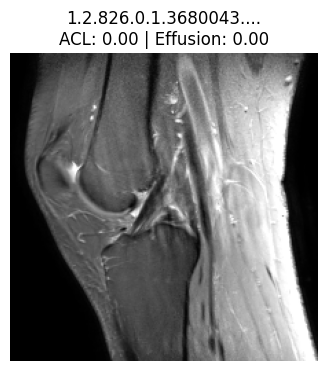

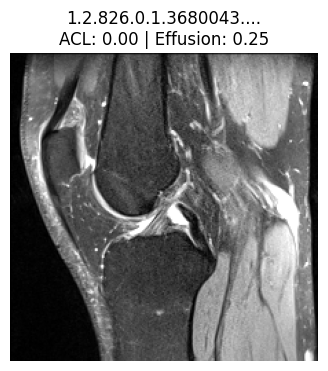

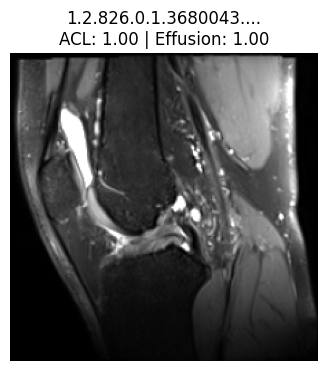

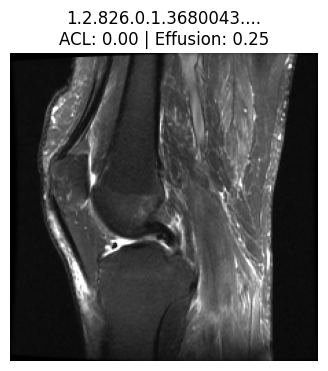

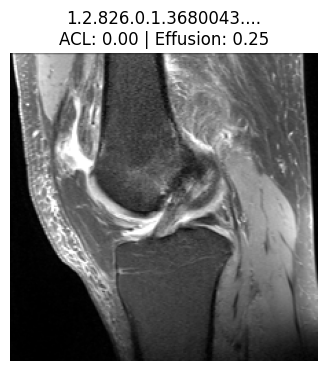

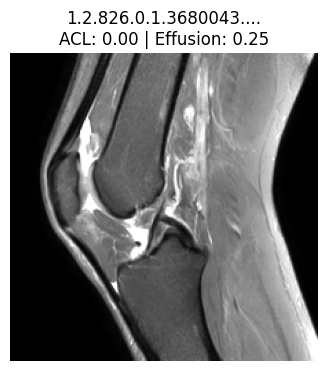

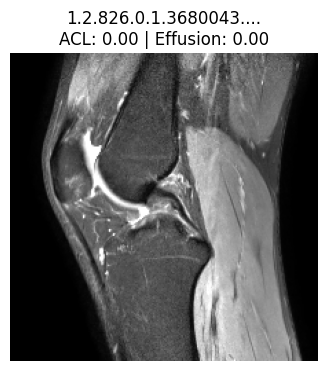

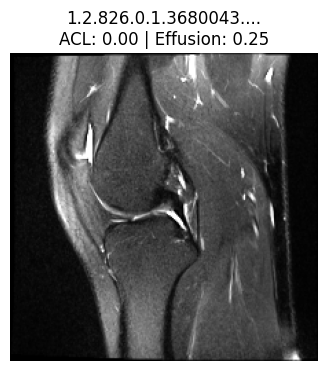

In [12]:
images_batch, labels_batch, ids_batch = next(
    iter(train_loader)
)

for i in range(8):

    # Select the middle of the 24 sagittal slices.
    middle_slice = images_batch[i, 12]

    plt.figure(figsize=(4, 4))

    plt.imshow(
        middle_slice,
        cmap="gray"
    )

    plt.title(
        f"{ids_batch[i][:20]}...\n"
        f"ACL: {labels_batch[i, 0]:.2f} | "
        f"Effusion: {labels_batch[i, 7]:.2f}"
    )

    plt.axis("off")
    plt.show()

## 12. Target Distribution

The mean target value is calculated for each abnormality across the training dataset.

Because the current dataset contains soft labels, these values should be interpreted as average target values rather than exact positive-case percentages.

This check helps identify class imbalance before model training.

In [13]:
all_labels = []

for _, labels_batch, _ in train_loader:
    all_labels.append(labels_batch)

all_labels = torch.cat(
    all_labels,
    dim=0
)

label_means = all_labels.mean(dim=0)

print("Average training target value:\n")

for label_name, mean_value in zip(
    LABELS,
    label_means
):
    print(
        f"{label_name:<20} "
        f"{mean_value:.4f}"
    )

Average training target value:

ACL                  0.1028
MCL                  0.0460
Medial Meniscus      0.3429
Lateral Meniscus     0.1526
Medial OA            0.2841
Lateral OA           0.1610
PF OA                0.2982
Effusion             0.2300
Synovitis            0.1231
Baker's              0.2843
Contusion            0.2042
Fracture             0.0714


## 13. DataLoader Performance

The DataLoader is timed without running model inference or training.

This provides a baseline measurement of how long it takes to load one complete training epoch from disk.

In [14]:
start_time = time.time()

num_batches = 0

for _, _, _ in train_loader:
    num_batches += 1

elapsed_time = time.time() - start_time

print("Batches loaded:", num_batches)
print(
    "Loading time:",
    round(elapsed_time, 2),
    "seconds"
)

Batches loaded: 128
Loading time: 23.2 seconds


## Data Pipeline Summary

The sagittal MRI data pipeline is functioning correctly.

### Validation results

- 4,093 training studies
- 56 validation studies
- 4,149 total usable studies
- no overlap between training and validation IDs
- MRI tensors have shape `(24, 224, 224)`
- each study contains 12 target values
- Dataset labels match the manifest
- DataLoader batches have shape `(32, 24, 224, 224)`
- MRI files were visually inspected and appear valid
- class imbalance was measured
- one full DataLoader pass takes approximately 21 seconds

### Interface for model training

Each training batch returns:

```text
images: (batch_size, 24, 224, 224)
labels: (batch_size, 12)
ids:    batch_size StudyInstanceUID values